In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, auc, f1_score, hamming_loss

Loading ground truth...
Loading model predictions...


,Model,Macro AUC,Macro F1,AUC_CD,AUC_HYP,AUC_MI,AUC_NORM,AUC_STTC
0,XGBoost (Tabular Limb),0.7864,0.4586,0.7874,0.7739,0.7243,0.8362,0.8102
1,Random Forest (Tabular Limb),0.7780,0.4156,0.7862,0.7689,0.7254,0.8215,0.7878
2,Lightweight 1D-CNN (TinyML),0.8302,0.5378,0.8143,0.7935,0.7846,0.8872,0.8714
3,Time-Freq 2D-CNN (STFT),0.7851,0.4346,0.7517,0.7721,0.7300,0.8441,0.8274
4,Deep ResNet + Attention (SOTA),0.8310,0.5364,0.8104,0.7986,0.7848,0.8901,0.8711


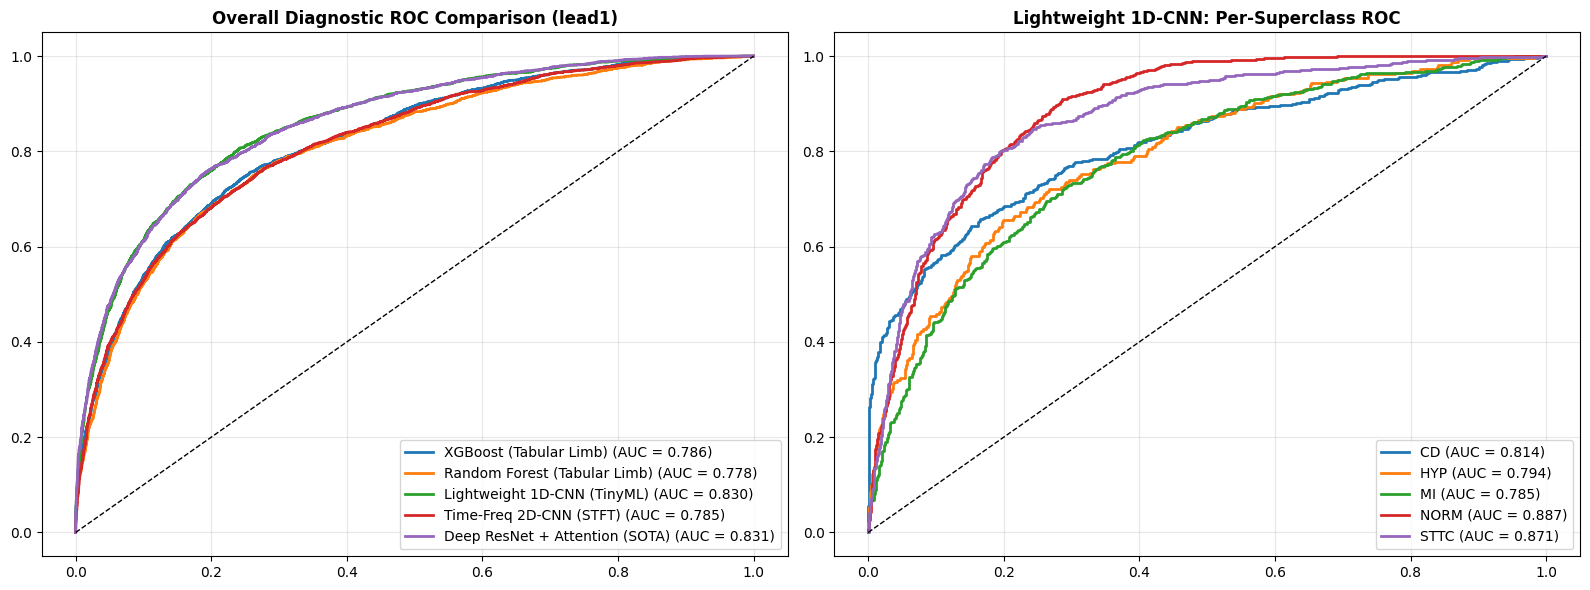

In [2]:
# 1. Load Ground Truth from Cache
print("Loading ground truth...")
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in (Path.cwd(), *Path.cwd().parents)
                            if (p / "scripts" / "project.py").exists()) / "scripts"))
from project import *  # ROOT, CACHE_FILE, LEAD_SET, MODELS_DIR, RESULTS_DIR, load_cache, ...
base_cache = np.load(CACHE_FILE, allow_pickle=True)
y_test = base_cache["y_test"]
class_names = base_cache["class_names"]

# 2. Load Predictions from all previous notebooks
print("Loading model predictions...")
preds_class = np.load(RESULTS_DIR / "preds_classical.npz")
preds_1d = np.load(RESULTS_DIR / "preds_1dcnn.npz")
preds_2d = np.load(RESULTS_DIR / "preds_2dcnn.npz")
preds_sota = np.load(RESULTS_DIR / "preds_sota.npz")

all_predictions = {
    "XGBoost (Tabular Limb)": preds_class["xgb"],
    "Random Forest (Tabular Limb)": preds_class["rf"],
    "Lightweight 1D-CNN (TinyML)": preds_1d["cnn1d"],
    "Time-Freq 2D-CNN (STFT)": preds_2d["cnn2d"],
    "Deep ResNet + Attention (SOTA)": preds_sota["sota"]
}

# 3. Generate Metrics Table
summary_records = []
for model_name, preds in all_predictions.items():
    macro_auc = roc_auc_score(y_test, preds, average="macro")
    micro_auc = roc_auc_score(y_test, preds, average="micro")
    per_class_auc = roc_auc_score(y_test, preds, average=None)
    
    bin_preds = (preds >= 0.5).astype(int)
    f1_macro = f1_score(y_test, bin_preds, average="macro", zero_division=0)
    
    record = {"Model": model_name, "Macro AUC": round(macro_auc, 4), "Macro F1": round(f1_macro, 4)}
    for idx, cname in enumerate(class_names):
        record[f"AUC_{cname}"] = round(per_class_auc[idx], 4)
    summary_records.append(record)

metrics_df = pd.DataFrame(summary_records)
display(metrics_df)
metrics_df.to_csv(RESULTS_DIR / "metrics_summary.csv", index=False)

# 4. Generate ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: Macro ROC Comparison
for name, preds in all_predictions.items():
    fpr, tpr, _ = roc_curve(y_test.ravel(), preds.ravel())
    score = roc_auc_score(y_test, preds, average="macro")
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {score:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title(f"Overall Diagnostic ROC Comparison ({LEAD_SET})", fontweight='bold')
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Plot B: Lightweight 1D-CNN Per-Class ROC
chosen_preds = all_predictions["Lightweight 1D-CNN (TinyML)"]
for idx, cname in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test[:, idx], chosen_preds[:, idx])
    axes[1].plot(fpr, tpr, lw=2, label=f"{cname} (AUC = {auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_title("Lightweight 1D-CNN: Per-Superclass ROC", fontweight='bold')
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "presentation_roc_comparison.png", dpi=300)
plt.show()